In [1]:
import os
import glob
import shutil

import numpy as np
import cv2
import matplotlib.pyplot as plt
import yaml
from tqdm.contrib.concurrent import thread_map# or thread_map

In [2]:
def create_project_file(file_pth: str, dataset_pth: str, label_mapping: dict, val_folder: str = "images/val") -> None:
    data = {
        "path": dataset_pth,
        "train": "images/train",
        "val": val_folder,
        "kpt_shape": [1, 2],
    }

    with open(file_pth, "wt") as f:
        yaml.dump(data, f, sort_keys=False, default_flow_style=None)
    
    with open(file_pth, "at") as f:
        yaml.dump({"names": label_mapping}, f, sort_keys=False)

In [3]:
def get_files_glob(directory, ext="*.txt"):
    pattern = os.path.join(directory, '**', ext)
    txt_files = glob.glob(pattern, recursive=True)
    return txt_files

In [4]:
def clahe(img):
    # Improve contrast using histogram equalization (adaptive for better results)
    lab = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8,8))
    l = clahe.apply(l)
    enhanced_image = cv2.merge((l, a, b))
    enhanced_image = cv2.cvtColor(enhanced_image, cv2.COLOR_LAB2BGR)
    return enhanced_image

def awb_avg(img):
    result = cv2.cvtColor(img.copy(), cv2.COLOR_BGR2LAB)
    avg_a = np.average(result[:, :, 1])
    avg_b = np.average(result[:, :, 2])
    result[:, :, 1] = result[:, :, 1] - ((avg_a - 128) * (result[:, :, 0] / 255.0) * 1.1)
    result[:, :, 2] = result[:, :, 2] - ((avg_b - 128) * (result[:, :, 0] / 255.0) * 1.1)
    result = cv2.cvtColor(result, cv2.COLOR_LAB2BGR)
    return result

In [5]:
BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_3_margin_15/images/train"

img_paths = glob.glob(os.path.join(BASE_PTH, "*.jpg"))
len(img_paths)

1307

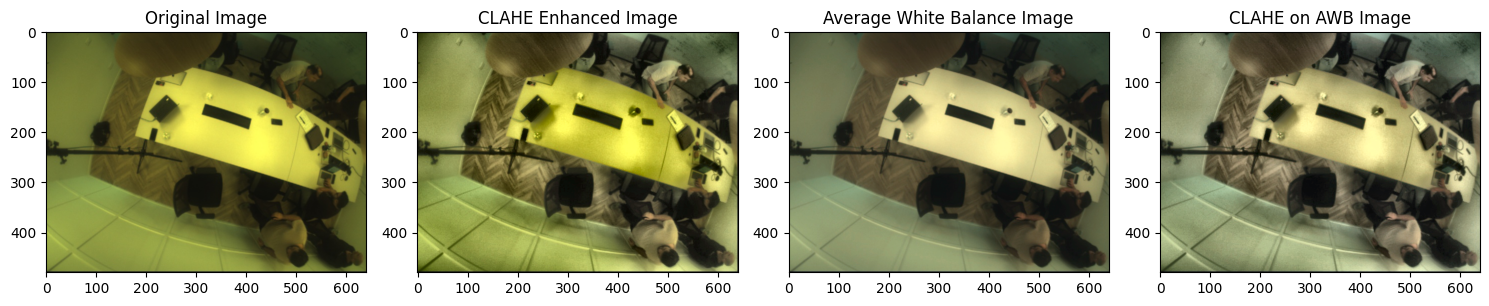

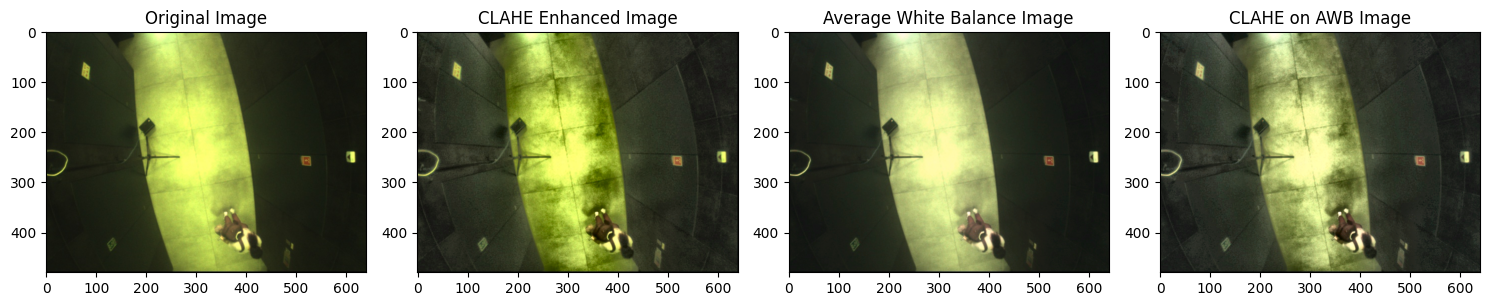

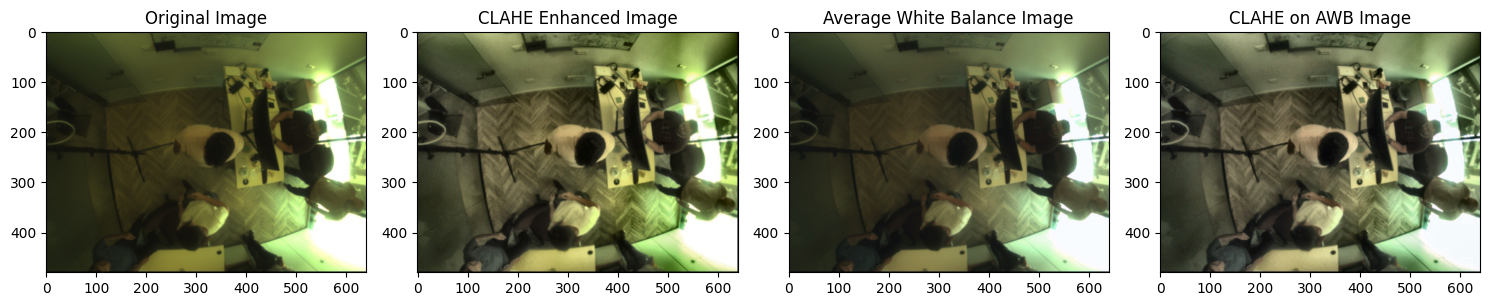

In [6]:
for i in img_paths[:3]:
    img = cv2.imread(i)

    # Apply white balance and contrast enhancement
    img_clahe = clahe(img)
    img_avg = awb_avg(img)
    imgavg_clahe = clahe(img_avg)

    # Display the images
    plt.figure(figsize=(15, 6))
    plt.subplot(1, 4, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('Original Image')
    
    plt.subplot(1, 4, 2)
    plt.imshow(cv2.cvtColor(img_clahe, cv2.COLOR_BGR2RGB))
    plt.title('CLAHE Enhanced Image')
    
    plt.subplot(1, 4, 3)
    plt.imshow(cv2.cvtColor(img_avg, cv2.COLOR_BGR2RGB))
    plt.title('Average White Balance Image')
    
    plt.subplot(1, 4, 4)
    plt.imshow(cv2.cvtColor(imgavg_clahe, cv2.COLOR_BGR2RGB))
    plt.title('CLAHE on AWB Image')
    plt.tight_layout()
    
    plt.show()

In [7]:
BASE_PTH = "/home/klymy/data/cam4_revB/yolo_dataset"
BASE_DATASET = "batch1_3_margin_15"
PROCESSED_DATASETS = ["batch1_3_margin_15_awb", "batch1_3_margin_15_awb_clahe"]

SUBSETS = ["train", "val", "holdout"]

In [8]:
def process_file(pth):
    img = cv2.imread(pth)
    res = awb_avg(img)
    cv2.imwrite(pth, res)

    return 1

def process_file_clahe(pth):
    img = cv2.imread(pth)
    res = awb_avg(img)
    res = clahe(res)
    cv2.imwrite(pth, res)


    return 1

In [9]:
for dataset_pth, f in zip(PROCESSED_DATASETS, [process_file, process_file_clahe]):
    src_pth = os.path.join(BASE_PTH, BASE_DATASET)
    dst_pth = os.path.join(BASE_PTH, dataset_pth)
    if os.path.exists(dst_pth):
        shutil.rmtree(dst_pth)
    shutil.copytree(src_pth, dst_pth)

    cache_files = get_files_glob(dst_pth, "*.cache")
    for i in cache_files:
        os.remove(i)
    
    # create project file
    create_project_file(os.path.join(dst_pth, "project.yaml"), dst_pth, {0: "person"})
    create_project_file(os.path.join(dst_pth, "project_holdout.yaml"), dst_pth, {0: "person"}, "images/holdout")
    
    img_pths = get_files_glob(os.path.join(dst_pth, "images"), "*.jpg")
    print(len(img_pths))

    r = thread_map(f, img_pths, max_workers=8)
    count = 0
    for i in r:
        count += i

    print(count == len(img_pths))

1600


  0%|          | 0/1600 [00:00<?, ?it/s]

True
1600


  0%|          | 0/1600 [00:00<?, ?it/s]

True
